# Load cell zero (ADC tare) drift test

Overnight run with nothing on the load cell, no calibration loaded (`NO_CAL`).
This notebook plots the raw ADC zero over time, flags spikes, and checks how much of the drift tracks temperature.

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

CSV_PATH = "lys1.csv"   # <-- change to your logger file

# Spike detection: points further than this many robust SDs (MAD-based) from a rolling median
SPIKE_WINDOW = 5      # samples (odd number)
SPIKE_THRESH = 5.0

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## Load data

In [14]:
df = pd.read_csv(CSV_PATH, na_values=["NaN", "nan", ""])
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)
df["status"] = df["status"].fillna("")
df["hours"] = (df["timestamp"] - df["timestamp"].iloc[0]).dt.total_seconds() / 3600

print(f"{len(df)} records, {df['timestamp'].min()} -> {df['timestamp'].max()} "
      f"({df['hours'].iloc[-1]:.2f} h), boot sessions: {sorted(df['boot_session'].unique())}")
df.head()

53 records, 2026-10-15 13:27:25 -> 2026-10-16 07:47:52 (18.34 h), boot sessions: [1]


,boot_session,elapsed_sec,timestamp,avg_temperature_C,avg_humidity_pct,avg_raw_adc,avg_weight_g,total_tips,status,hours
0,1,902,2026-10-15 13:27:25,21.5,94.5,30319.0,NaN,0,NO_CAL,0.000000
1,1,1802,2026-10-15 13:42:19,22.2,92.4,30723.0,NaN,0,NO_CAL,0.248333
2,1,2702,2026-10-15 13:57:11,23.8,84.1,30276.0,NaN,0,NO_CAL,0.496111
3,1,3602,2026-10-15 14:12:04,21.8,92.0,30461.0,NaN,0,NO_CAL,0.744167
4,1,4502,2026-10-15 14:26:55,21.8,91.9,30518.0,NaN,0,NO_CAL,0.991667


## Flag spikes
A rolling median + MAD filter, so a single bad reading (e.g. a stuck/garbled ADC read) doesn't distort the drift estimate. Flagged points are still plotted, just marked.

In [15]:
adc = df["avg_raw_adc"].astype(float)
roll_med = adc.rolling(SPIKE_WINDOW, center=True, min_periods=1).median()
resid = adc - roll_med
mad = (resid - resid.median()).abs().median()
robust_sd = 1.4826 * mad if mad > 0 else resid.abs().median() + 1e-9
df["spike"] = (resid.abs() / robust_sd) > SPIKE_THRESH
# Also treat the very first sample after power-on as warm-up
df["warmup"] = df["status"].str.contains("BOOT")

clean = df[~df["spike"] & ~df["warmup"]].copy()
print(f"Spikes flagged: {df['spike'].sum()}  |  warm-up samples excluded: {df['warmup'].sum()}")
df.loc[df["spike"], ["timestamp", "avg_raw_adc", "status"]]

Spikes flagged: 14  |  warm-up samples excluded: 0


,timestamp,avg_raw_adc,status
1,2026-10-15 13:42:19,30723.0,NO_CAL
2,2026-10-15 13:57:11,30276.0,NO_CAL
3,2026-10-15 14:12:04,30461.0,NO_CAL
9,2026-10-15 15:41:17,31125.0,NO_CAL
11,2026-10-15 16:25:54,30654.0,NO_CAL
20,2026-10-15 18:39:45,31072.0,NO_CAL
22,2026-10-15 19:09:30,31037.0,NO_CAL
24,2026-10-15 19:39:15,31055.0,NO_CAL
30,2026-10-15 21:08:32,31071.0,NO_CAL
37,2026-10-16 04:04:44,31311.0,NO_CAL


## Summary statistics (clean samples)

In [16]:
c = clean["avg_raw_adc"]
if len(clean) >= 2:
    slope, intercept = np.polyfit(clean["hours"], c, 1)
else:
    slope, intercept = np.nan, np.nan

summary = pd.Series({
    "n samples": len(clean),
    "mean ADC": c.mean(),
    "std ADC (noise)": c.std(),
    "peak-to-peak ADC": c.max() - c.min(),
    "linear drift (counts/h)": slope,
    "total drift over run (counts)": slope * (clean["hours"].max() - clean["hours"].min()),
    "temp range (°C)": clean["avg_temperature_C"].max() - clean["avg_temperature_C"].min(),
})
summary.round(2)

n samples                           39.00
mean ADC                         31050.28
std ADC (noise)                    262.12
peak-to-peak ADC                  1021.00
linear drift (counts/h)             38.69
total drift over run (counts)      709.60
temp range (°C)                      4.30
dtype: float64

## Zero drift over time, with temperature and humidity

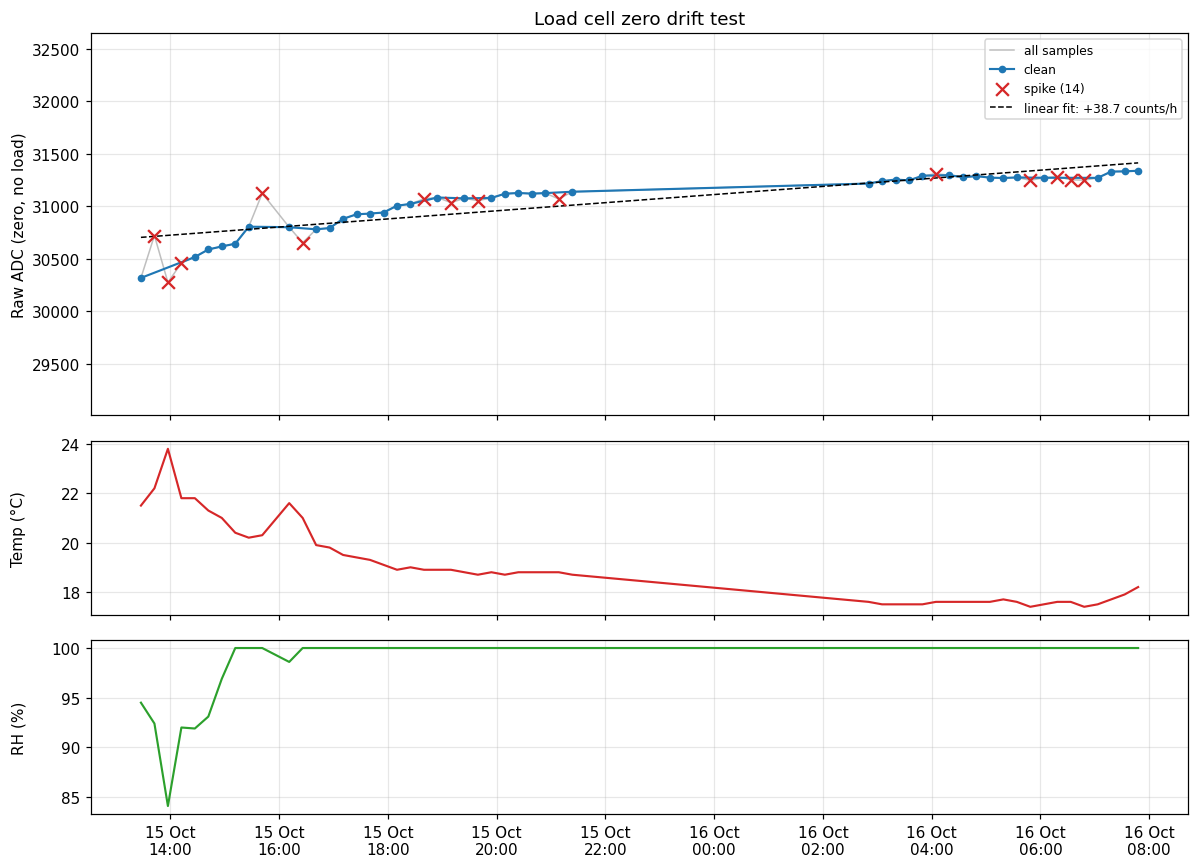

In [17]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True,
                         gridspec_kw={"height_ratios": [2.2, 1, 1]})

ax = axes[0]
ax.plot(df["timestamp"], df["avg_raw_adc"], color="0.75", lw=1, zorder=1, label="all samples")
ax.plot(clean["timestamp"], clean["avg_raw_adc"], "o-", color="tab:blue", ms=4, lw=1.4,
        zorder=2, label="clean")
if df["spike"].any():
    s = df[df["spike"]]
    ax.scatter(s["timestamp"], s["avg_raw_adc"], marker="x", s=70, color="tab:red", zorder=3,
               label=f"spike ({len(s)})")
if df["warmup"].any():
    w = df[df["warmup"]]
    ax.scatter(w["timestamp"], w["avg_raw_adc"], marker="s", s=40, facecolors="none",
               edgecolors="tab:orange", zorder=3, label="power-on / warm-up")
if np.isfinite(slope):
    ax.plot(clean["timestamp"], intercept + slope * clean["hours"], "--", color="k", lw=1,
            label=f"linear fit: {slope:+.1f} counts/h")

# Zoom y-axis to the clean data so spikes don't flatten the drift
if len(clean):
    pad = max(5 * c.std(), 50)
    ax.set_ylim(c.min() - pad, c.max() + pad)
    off = df[df["spike"] & ((df["avg_raw_adc"] > c.max() + pad) | (df["avg_raw_adc"] < c.min() - pad))]
    for _, r in off.iterrows():
        y = c.max() + pad * 0.9 if r["avg_raw_adc"] > c.max() else c.min() - pad * 0.9
        ax.annotate(f"{int(r['avg_raw_adc'])} (off-scale)", (r["timestamp"], y), fontsize=8,
                    color="tab:red", ha="center", va="top" if y > c.mean() else "bottom")

# Mark reboots
for t in df.loc[df["boot_session"].diff().fillna(0) != 0, "timestamp"]:
    for a in axes:
        a.axvline(t, color="tab:purple", ls=":", lw=1)

ax.set_ylabel("Raw ADC (zero, no load)")
ax.set_title("Load cell zero drift test")
ax.legend(loc="best", fontsize=8)

axes[1].plot(df["timestamp"], df["avg_temperature_C"], color="tab:red", lw=1.4)
axes[1].set_ylabel("Temp (°C)")
axes[2].plot(df["timestamp"], df["avg_humidity_pct"], color="tab:green", lw=1.4)
axes[2].set_ylabel("RH (%)")

axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
fig.align_ylabels(axes)
fig.tight_layout()
plt.show()

## Temperature sensitivity
If the zero tracks temperature, the slope here is your thermal coefficient (counts/°C) — useful for a temperature compensation term later.

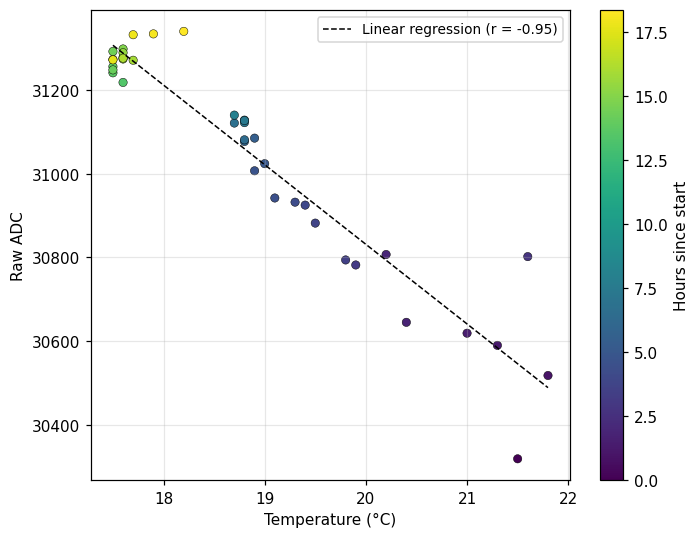

In [18]:
fig, ax = plt.subplots(figsize=(6.5, 5))
sc = ax.scatter(clean["avg_temperature_C"], clean["avg_raw_adc"], c=clean["hours"],
                cmap="viridis", s=30, edgecolor="k", lw=0.3)
fig.colorbar(sc, ax=ax, label="Hours since start")

if clean["avg_temperature_C"].nunique() > 1:
    k, b = np.polyfit(clean["avg_temperature_C"], clean["avg_raw_adc"], 1)
    r = clean[["avg_temperature_C", "avg_raw_adc"]].corr().iloc[0, 1]
    tx = np.linspace(clean["avg_temperature_C"].min(), clean["avg_temperature_C"].max(), 50)
    ax.plot(tx, k * tx + b, "k--", lw=1, label=f"Linear regression (r = {r:.2f})")
    ax.legend(fontsize=9)

ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Raw ADC")
fig.tight_layout()
plt.show()

## Detrended noise
What's left after removing the linear time drift — this is the short-term noise floor you'd see on a stable zero.

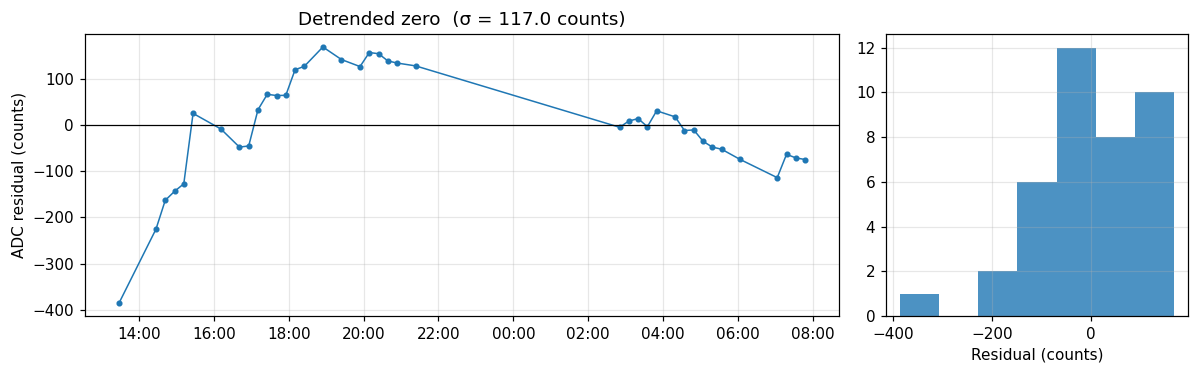

In [19]:
if np.isfinite(slope):
    clean["detrended"] = clean["avg_raw_adc"] - (intercept + slope * clean["hours"])
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5), gridspec_kw={"width_ratios": [2.5, 1]})
    a1.plot(clean["timestamp"], clean["detrended"], "o-", ms=3, lw=1)
    a1.axhline(0, color="k", lw=0.8)
    a1.set_ylabel("ADC residual (counts)")
    a1.set_title(f"Detrended zero  (σ = {clean['detrended'].std():.1f} counts)")
    a1.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    a2.hist(clean["detrended"], bins=max(5, len(clean) // 5), color="tab:blue", alpha=0.8)
    a2.set_xlabel("Residual (counts)")
    fig.tight_layout()
    plt.show()

## Remove invalid data
The plots above show the raw log. This section keeps only rows whose status is exactly `NO_CAL` and removes every row with any other status flag (e.g. `BOOT_POWERON`, `HX_0of10`, `HX_5of10`), saves the cleaned log, and repeats the analysis.

In [20]:
from pathlib import Path

KEEP_STATUS = "NO_CAL"   # rows with any other status are removed

status = df["status"].str.strip()
df["remove"] = status != KEEP_STATUS
df["reason"] = np.where(df["remove"], "status: " + status, "")
dclean = df[~df["remove"]].copy()

print(f"Removed {df['remove'].sum()} of {len(df)} rows, kept {len(dclean)}")
display(df.loc[df["remove"], "status"].value_counts().rename("rows removed").to_frame())
display(df.loc[df["remove"], ["timestamp", "avg_temperature_C", "avg_raw_adc", "status"]])

Removed 0 of 53 rows, kept 53


,rows removed
status,


,timestamp,avg_temperature_C,avg_raw_adc,status


In [21]:
# Save the cleaned log (original columns) and a log of what was removed
src = Path(CSV_PATH)
clean_path = src.with_name(src.stem + "_clean.csv")
removed_path = src.with_name(src.stem + "_removed.csv")
orig_cols = [c for c in pd.read_csv(CSV_PATH, nrows=0).columns]
dclean[orig_cols].to_csv(clean_path, index=False)
df.loc[df["remove"], orig_cols + ["reason"]].to_csv(removed_path, index=False)
print(f"Saved {len(dclean)} rows to {clean_path}")
print(f"Saved {df['remove'].sum()} removed rows (with reasons) to {removed_path}")

Saved 53 rows to lys1_clean.csv
Saved 0 removed rows (with reasons) to lys1_removed.csv


## Cleaned data: zero over time

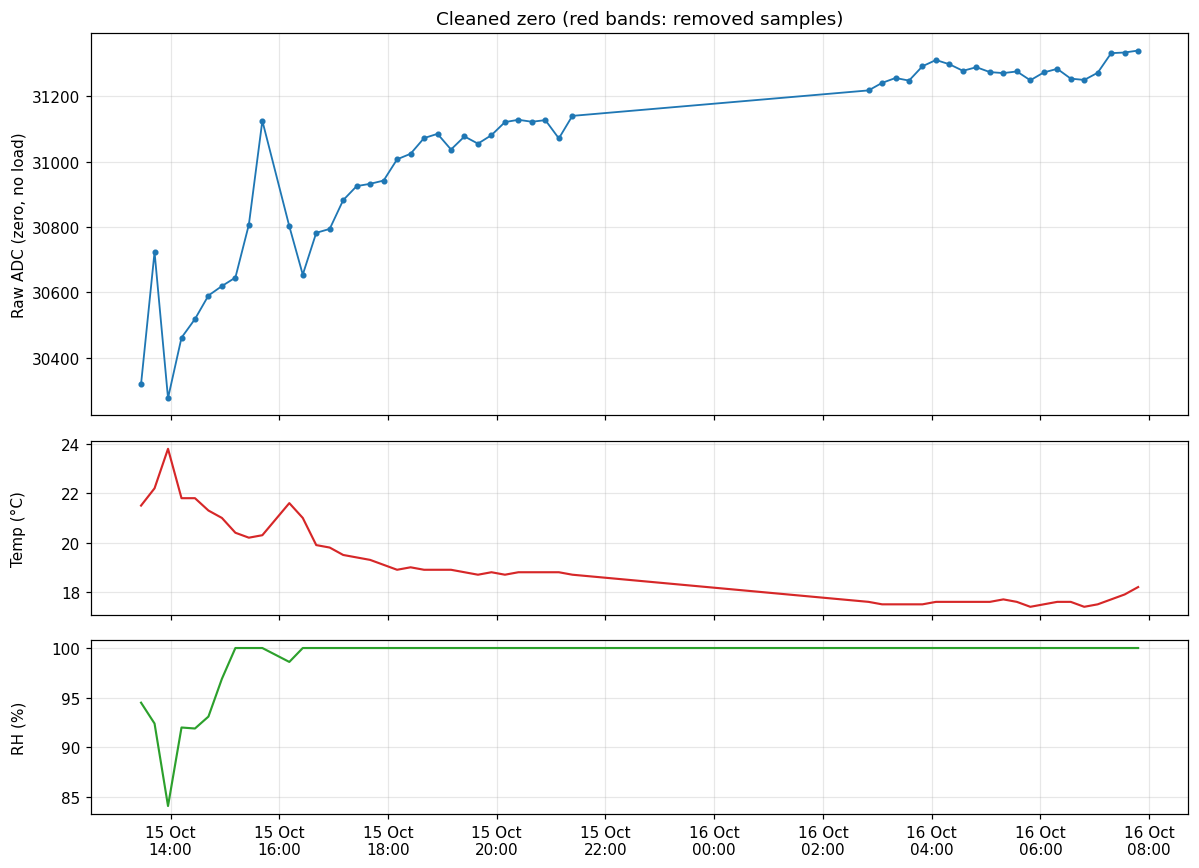

In [22]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True,
                         gridspec_kw={"height_ratios": [2.2, 1, 1]})
axes[0].plot(dclean["timestamp"], dclean["avg_raw_adc"], "o-", ms=3, lw=1.2, color="tab:blue")
# shade gaps left by removed data
rem = df[df["remove"]]
for t in rem["timestamp"]:
    axes[0].axvspan(t - pd.Timedelta(minutes=7.5), t + pd.Timedelta(minutes=7.5),
                    color="tab:red", alpha=0.12, lw=0)
axes[0].set_ylabel("Raw ADC (zero, no load)")
axes[0].set_title("Cleaned zero (red bands: removed samples)")
axes[1].plot(dclean["timestamp"], dclean["avg_temperature_C"], color="tab:red", lw=1.4)
axes[1].set_ylabel("Temp (°C)")
axes[2].plot(dclean["timestamp"], dclean["avg_humidity_pct"], color="tab:green", lw=1.4)
axes[2].set_ylabel("RH (%)")
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
fig.align_ylabels(axes); fig.tight_layout(); plt.show()

## Cleaned data: temperature regression

Regression (cleaned): -136.0 counts/°C, r = -0.855, R² = 0.731, residual RMSE = 142 counts, n = 54
Joint fit: -71.8 counts/°C and +21.9 counts/h of time drift


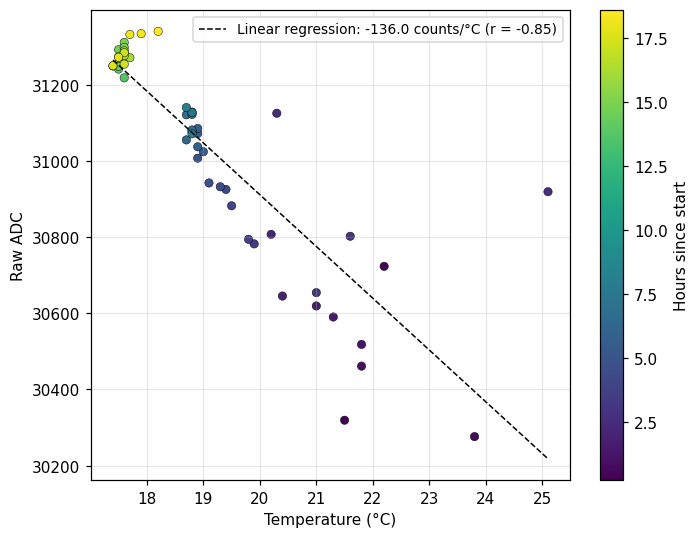

In [11]:
Tc, Zc = dclean["avg_temperature_C"].values, dclean["avg_raw_adc"].values
k, b = np.polyfit(Tc, Zc, 1)
r = np.corrcoef(Tc, Zc)[0, 1]
rmse = np.sqrt(((Zc - (k * Tc + b))**2).mean())

# Time and temperature fitted together, to check whether slow drift inflates the temperature slope
hrs = dclean["hours"].values
X = np.column_stack([Tc, hrs, np.ones(len(dclean))])
(k_joint, drift_h, _), *_ = np.linalg.lstsq(X, Zc, rcond=None)

print(f"Regression (cleaned): {k:+.1f} counts/°C, r = {r:.3f}, R² = {r**2:.3f}, "
      f"residual RMSE = {rmse:.0f} counts, n = {len(dclean)}")
print(f"Joint fit: {k_joint:+.1f} counts/°C and {drift_h:+.1f} counts/h of time drift")

fig, ax = plt.subplots(figsize=(6.5, 5))
sc = ax.scatter(Tc, Zc, c=hrs, cmap="viridis", s=30, edgecolor="k", lw=0.3)
fig.colorbar(sc, ax=ax, label="Hours since start")
tx = np.linspace(Tc.min(), Tc.max(), 50)
ax.plot(tx, k * tx + b, "k--", lw=1,
        label=f"Linear regression: {k:+.1f} counts/°C (r = {r:.2f})")
ax.set_xlabel("Temperature (°C)"); ax.set_ylabel("Raw ADC")
ax.legend(fontsize=9); fig.tight_layout(); plt.show()

In [12]:
# ---- Daily drift of the unloaded zero ----
COUNTS_PER_G = 87.7     # calibration slope (counts/g) <-- set for THIS load cell
ALPHA = k               # zero temperature coefficient (counts/°C): cleaned regression above

# Use the cleaned data from the section above
d = dclean[dclean["avg_temperature_C"].notna()].copy()

# Temperature-corrected zero, referenced to the mean temperature
T0 = d["avg_temperature_C"].mean()
d["adc_tc"] = d["avg_raw_adc"] - ALPHA * (d["avg_temperature_C"] - T0)

# 1) Diurnal swing per calendar day (raw vs temperature-corrected)
daily = d.groupby(d["timestamp"].dt.date).agg(
    n=("avg_raw_adc", "size"),
    T_min=("avg_temperature_C", "min"), T_max=("avg_temperature_C", "max"),
    raw_range_counts=("avg_raw_adc", lambda x: x.max() - x.min()),
    tc_range_counts=("adc_tc", lambda x: x.max() - x.min()),
)
daily["T_range"] = daily["T_max"] - daily["T_min"]
daily["raw_range_g"] = daily["raw_range_counts"] / COUNTS_PER_G
daily["tc_range_g"] = daily["tc_range_counts"] / COUNTS_PER_G
display(daily.round(2))

# 2) Long-term drift per day: linear trend in time
#    (a) raw zero, (b) temperature-corrected zero, (c) time and temperature fitted jointly
days = d["hours"].values / 24
slope_raw = np.polyfit(days, d["avg_raw_adc"], 1)[0]
slope_tc = np.polyfit(days, d["adc_tc"], 1)[0]
X = np.column_stack([days, d["avg_temperature_C"], np.ones(len(d))])
(slope_joint, alpha_joint, _), *_ = np.linalg.lstsq(X, d["avg_raw_adc"].values, rcond=None)

span_h = d["hours"].iloc[-1] - d["hours"].iloc[0]
print(f"Record length: {span_h:.1f} h ({len(d)} clean samples)")
for name, s in [("raw zero", slope_raw),
                (f"temperature-corrected (α = {ALPHA:.1f})", slope_tc),
                (f"joint fit (α fitted = {alpha_joint:.1f})", slope_joint)]:
    print(f"  Drift, {name:38s}: {s:+8.1f} counts/day = {s / COUNTS_PER_G:+6.2f} g/day")
if span_h < 24:
    print("⚠️  Record is shorter than a day: per-day values are extrapolated.")

,n,T_min,T_max,raw_range_counts,tc_range_counts,T_range,raw_range_g,tc_range_g
timestamp,,,,,,,,
2026-10-15,33,18.7,25.1,864.0,1089.53,6.4,9.85,12.42
2026-10-16,21,17.4,18.2,122.0,203.59,0.8,1.39,2.32


Record length: 18.3 h (54 clean samples)
  Drift, raw zero                              :   +922.3 counts/day = +10.52 g/day
  Drift, temperature-corrected (α = -136.0)    :   +170.3 counts/day =  +1.94 g/day
  Drift, joint fit (α fitted = -71.8)          :   +525.2 counts/day =  +5.99 g/day
⚠️  Record is shorter than a day: per-day values are extrapolated.
